In [2]:
import pandas as pd

df = pd.read_excel("cleaned_sales_dataset.xlsx", sheet_name="Cleaned Data")

df.head()

,Customer Name,State,Product,Units Sold,Unit Price,Total Sale,Sale Date,Sales Channel
0,NaN,Rivers,Keyboard,NaN,NaN,NaN,2025-04-27,Online
1,Allison Hill,Lagos,Headphones,NaN,267992.94,NaN,2024-03-15,Wholesale
2,Noah Rhodes,Anambra,Keyboard,NaN,42364.41,NaN,2024-12-10,Missing
3,Angie HendeDrseolnta,Delta,Keyboard,NaN,279444.94,NaN,2024-04-05,Missing
4,Daniel WagnDerelta,Delta,Tablet,NaN,95899.74,NaN,2025-01-12,Missing


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column data types and non-missing values
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (550, 8)
<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer Name  507 non-null    str    
 1   State          550 non-null    str    
 2   Product        550 non-null    str    
 3   Units Sold     155 non-null    float64
 4   Unit Price     495 non-null    float64
 5   Total Sale     137 non-null    float64
 6   Sale Date      550 non-null    str    
 7   Sales Channel  550 non-null    str    
dtypes: float64(3), str(5)
memory usage: 34.5 KB

Missing values:
Customer Name     43
State              0
Product            0
Units Sold       395
Unit Price        55
Total Sale       413
Sale Date          0
Sales Channel      0
dtype: int64


In [4]:
# Calculate sales where both inputs are available
df["Calculated Sale"] = df["Units Sold"] * df["Unit Price"]

# Check how many calculated sales values are available
print("Available calculated sales:", df["Calculated Sale"].notna().sum())

# Display a few rows
df[["Units Sold", "Unit Price", "Total Sale", "Calculated Sale"]].head(10)

Available calculated sales: 137


,Units Sold,Unit Price,Total Sale,Calculated Sale
0,NaN,NaN,NaN,NaN
1,NaN,267992.94,NaN,NaN
2,NaN,42364.41,NaN,NaN
3,NaN,279444.94,NaN,NaN
4,NaN,95899.74,NaN,NaN
5,NaN,118189.90,NaN,NaN
6,36.0,185141.90,6665108.4,6665108.4
7,NaN,252859.28,NaN,NaN
8,NaN,178320.53,NaN,NaN
9,NaN,152440.84,NaN,NaN


In [5]:
# Calculate total sales from available calculated values
total_sales = df["Calculated Sale"].sum()

print("Total Sales:", round(total_sales, 2))

Total Sales: 969297752.08


In [6]:
average_order_value = df["Calculated Sale"].mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 7075166.07


In [7]:
# Calculate sales by product
top_products = (
    df.groupby("Product")["Calculated Sale"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Product:")
print(top_products)

Sales by Product:
Product
Keyboard      2.065577e+08
Phone         1.736678e+08
Tablet        1.621149e+08
Headphones    1.426256e+08
Monitor       1.207897e+08
Charger       1.030686e+08
Laptop        3.514419e+07
Camera        2.532931e+07
Name: Calculated Sale, dtype: float64


In [8]:
# Display sales values without scientific notation
pd.options.display.float_format = '{:,.2f}'.format

print(top_products)

Product
Keyboard     206,557,699.44
Phone        173,667,802.80
Tablet       162,114,871.22
Headphones   142,625,625.12
Monitor      120,789,697.51
Charger      103,068,554.06
Laptop        35,144,190.05
Camera        25,329,311.88
Name: Calculated Sale, dtype: float64


In [9]:
# Calculate sales by state
sales_by_state = (
    df.groupby("State")["Calculated Sale"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by State:")
print(sales_by_state)

Sales by State:
State
Kano          118,744,564.76
Rivers        118,217,308.00
Benue          83,651,542.02
Imo            72,269,678.92
Plateau        61,414,056.17
Kaduna         58,834,730.64
Niger          56,832,717.35
Osun           45,673,673.86
Lagos          44,548,407.02
Delta          42,018,365.26
Katsina        36,094,558.16
Enugu          34,518,737.93
Bauchi         33,982,869.24
Cross River    33,914,235.67
Abuja          33,383,113.98
Oyo            28,967,495.85
Borno          23,286,853.24
Ekiti          16,016,820.99
Sokoto         15,597,774.50
Anambra        11,330,248.52
Name: Calculated Sale, dtype: float64


In [10]:
# Calculate sales by channel
sales_by_channel = (
    df.groupby("Sales Channel")["Calculated Sale"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Channel:")
print(sales_by_channel)

Sales by Channel:
Sales Channel
Online      235,803,206.77
Retail      215,225,668.48
Missing     185,693,075.85
Wholesale   167,084,548.56
Direct      165,491,252.42
Name: Calculated Sale, dtype: float64


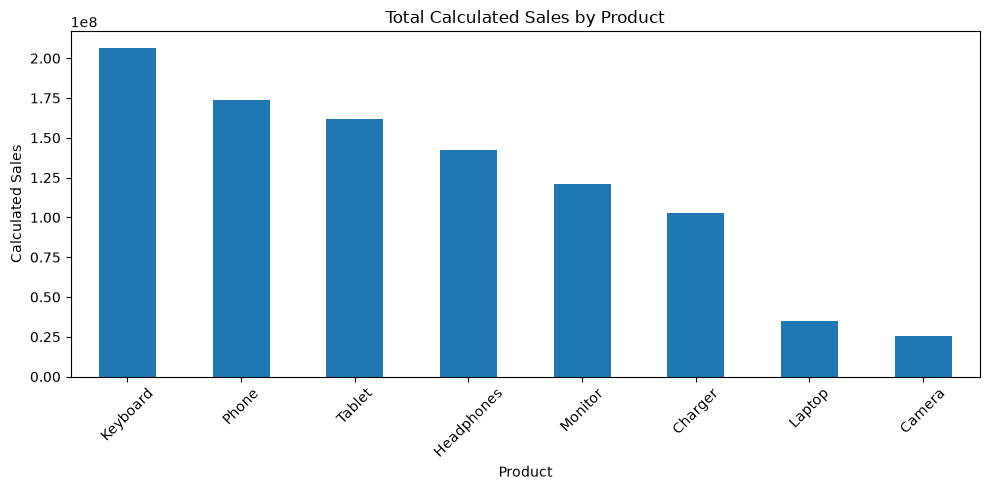

In [13]:
import matplotlib.pyplot as plt

# Bar chart: Sales by Product
top_products.plot(kind="bar", figsize=(10, 5))

plt.title("Total Calculated Sales by Product")
plt.xlabel("Product")
plt.ylabel("Calculated Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sales_by_product.png", dpi=300, bbox_inches="tight")
plt.show()

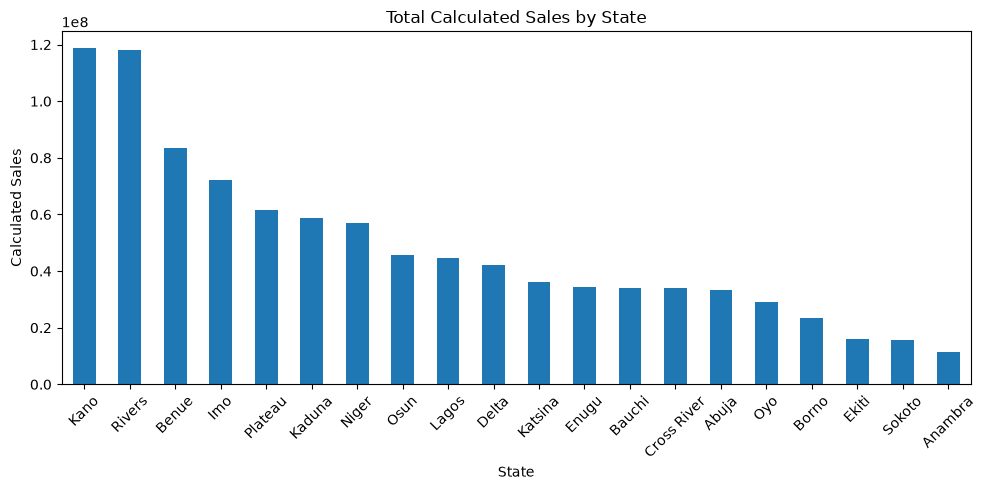

In [14]:
sales_by_state.plot(kind="bar", figsize=(10, 5))

plt.title("Total Calculated Sales by State")
plt.xlabel("State")
plt.ylabel("Calculated Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sales_by_state.png", dpi=300, bbox_inches="tight")
plt.show()